In [2]:
# pip install xarray netCDF4 pandas

In [2]:
import xarray as xr

ds = xr.open_dataset("data/mfwamglocep_2026020100_R20260202_00H.nc")

print(ds)

<xarray.Dataset> Size: 3GB
Dimensions:    (time: 4, latitude: 2041, longitude: 4320)
Coordinates:
  * time       (time) datetime64[ns] 32B 2026-02-01T03:00:00 ... 2026-02-01T1...
  * latitude   (latitude) float64 16kB -80.0 -79.92 -79.83 ... 89.83 89.92 90.0
  * longitude  (longitude) float64 35kB -180.0 -179.9 -179.8 ... 179.8 179.9
Data variables: (12/19)
    VHM0       (time, latitude, longitude) float32 141MB ...
    VHM0_WW    (time, latitude, longitude) float32 141MB ...
    VTM01_SW1  (time, latitude, longitude) float32 141MB ...
    VTM01_SW2  (time, latitude, longitude) float32 141MB ...
    VTM10      (time, latitude, longitude) float32 141MB ...
    VHM0_SW1   (time, latitude, longitude) float32 141MB ...
    ...         ...
    VTM01_WW   (time, latitude, longitude) float32 141MB ...
    VMDR_WW    (time, latitude, longitude) float32 141MB ...
    VMDR_SW1   (time, latitude, longitude) float32 141MB ...
    VMDR_SW2   (time, latitude, longitude) float32 141MB ...
    VMDR  

In [3]:
print(list(ds.data_vars))

['VHM0', 'VHM0_WW', 'VTM01_SW1', 'VTM01_SW2', 'VTM10', 'VHM0_SW1', 'VHM0_SW2', 'VTPK', 'VMXL', 'VSDX', 'VSDY', 'VCMX', 'VTM02', 'VTM01_WW', 'VMDR_WW', 'VMDR_SW1', 'VMDR_SW2', 'VMDR', 'VPED']


In [4]:
print(ds["VHM0_WW"].attrs["long_name"])

Spectral significant wind wave height


In [5]:
for var in ds.data_vars:
    print(var, ": ", ds[var].attrs["long_name"])

VHM0 :  Spectral significant wave height (Hm0)
VHM0_WW :  Spectral significant wind wave height
VTM01_SW1 :  Spectral moments (0,1) primary swell wave period
VTM01_SW2 :  Spectral moments (0,1) secondary swell wave period
VTM10 :  Spectral moments (-1,0) wave period (Tm-10)
VHM0_SW1 :  Spectral significant primary swell wave height
VHM0_SW2 :  Spectral significant secondary swell wave height
VTPK :  Wave period at spectral peak / peak period (Tp)
VMXL :  Height of the highest crest
VSDX :  Stokes drift U
VSDY :  Stokes drift V
VCMX :  Maximum crest trough wave height
VTM02 :  Spectral moments (0,2) wave period (Tm02)
VTM01_WW :  Spectral moments (0,1) wind wave period
VMDR_WW :  Mean wind wave direction from
VMDR_SW1 :  Mean primary swell wave direction from
VMDR_SW2 :  Mean secondary swell wave direction from
VMDR :  Mean wave direction from (Mdir)
VPED :  Wave principal direction at spectral peak


In [6]:
ds_filtered = ds.sel(
    longitude=slice(-6.0, 5.842),
    latitude=slice(43.276, 52.9)
)

print(ds_filtered)

<xarray.Dataset> Size: 5MB
Dimensions:    (time: 4, latitude: 115, longitude: 143)
Coordinates:
  * time       (time) datetime64[ns] 32B 2026-02-01T03:00:00 ... 2026-02-01T1...
  * latitude   (latitude) float64 920B 43.33 43.42 43.5 ... 52.67 52.75 52.83
  * longitude  (longitude) float64 1kB -6.0 -5.917 -5.833 ... 5.667 5.75 5.833
Data variables: (12/19)
    VHM0       (time, latitude, longitude) float32 263kB ...
    VHM0_WW    (time, latitude, longitude) float32 263kB ...
    VTM01_SW1  (time, latitude, longitude) float32 263kB ...
    VTM01_SW2  (time, latitude, longitude) float32 263kB ...
    VTM10      (time, latitude, longitude) float32 263kB ...
    VHM0_SW1   (time, latitude, longitude) float32 263kB ...
    ...         ...
    VTM01_WW   (time, latitude, longitude) float32 263kB ...
    VMDR_WW    (time, latitude, longitude) float32 263kB ...
    VMDR_SW1   (time, latitude, longitude) float32 263kB ...
    VMDR_SW2   (time, latitude, longitude) float32 263kB ...
    VMDR    

In [7]:
import numpy as np

In [8]:
g = 9.81

# Significant wave height
height = ds_filtered["VHM0"]

# Convert FROM direction into TO direction
direction = (ds_filtered["VMDR"] + 180) % 360
theta = np.deg2rad(direction)

# Estimated deep-water propagation speeds
phase_speed = g * ds_filtered["VTPK"] / (2 * np.pi)
group_speed = g * ds_filtered["VTPK"] / (4 * np.pi)

# Wave propagation vector components
u = group_speed * np.sin(theta)
v = group_speed * np.cos(theta)

ds_filtered["wave_u"] = u
ds_filtered["wave_v"] = v
ds_filtered["wave_speed"] = group_speed
ds_filtered["wave_direction"] = direction

In [9]:
ds_filtered

<xarray.Dataset> Size: 6MB
Dimensions:         (time: 4, latitude: 115, longitude: 143)
Coordinates:
  * time            (time) datetime64[ns] 32B 2026-02-01T03:00:00 ... 2026-02...
  * latitude        (latitude) float64 920B 43.33 43.42 43.5 ... 52.75 52.83
  * longitude       (longitude) float64 1kB -6.0 -5.917 -5.833 ... 5.75 5.833
Data variables: (12/23)
    VHM0            (time, latitude, longitude) float32 263kB ...
    VHM0_WW         (time, latitude, longitude) float32 263kB ...
    VTM01_SW1       (time, latitude, longitude) float32 263kB ...
    VTM01_SW2       (time, latitude, longitude) float32 263kB ...
    VTM10           (time, latitude, longitude) float32 263kB ...
    VHM0_SW1        (time, latitude, longitude) float32 263kB ...
    ...              ...
    VMDR            (time, latitude, longitude) float32 263kB nan nan ... nan
    VPED            (time, latitude, longitude) float32 263kB ...
    wave_u          (time, latitude, longitude) float32 263kB nan nan ... nan
    wave_v          (time, latitude, longitude) float32 263kB nan nan ... nan
    wave_speed      (time, latitude, longitude) float32 263kB nan nan ... nan
    wave_direction  (time, latitude, longitude) float32 263kB nan nan ... nan
Attributes: (12/16)
    Conventions:           CF-1.6
    product:               GLOBAL_ANALYSIS_FORECAST_WAV_001_027
    institution:           METEO-FRANCE
    references:            http://marine.copernicus.eu
    credit:                E.U. Copernicus Marine Service Information (CMEMS)
    contact:               servicedesk.cmems@mercator-ocean.eu
    ...                    ...
    geospatial_lon_step:   0.08332825
    geospatial_lon_units:  degree
    geospatial_lat_min:    -80.0
    geospatial_lat_max:    90.0
    geospatial_lat_step:   0.08333588
    geospatial_lat_units:  degree

In [10]:
columns = [
    "wave_u",
    "wave_v",
    "wave_speed",
    "wave_direction"
]

df = ds_filtered[columns].to_dataframe().reset_index()

# # Select only the required columns
df = df[["latitude", "longitude"] + columns]

# # Remove invalid or missing data points
df = df.dropna()

# # Export to CSV
df.to_csv("wave_movement.csv", index=False)

<Axes: title={'center': 'Wave Speed Over Time'}>

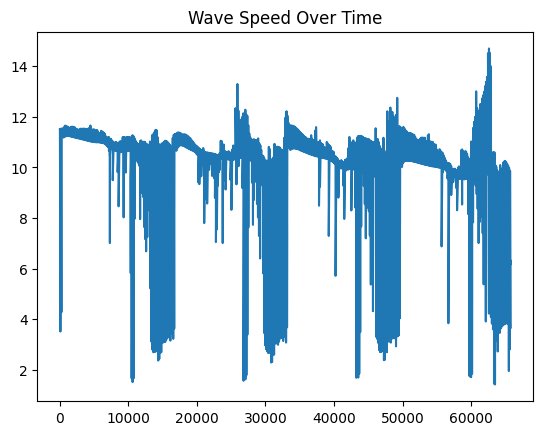

In [12]:
df["wave_speed"].plot(title="Wave Speed Over Time")

In [32]:
df["wave_direction"].min()

np.float32(0.0)

In [33]:
df["wave_direction"].max()

np.float32(359.89)

In [13]:
import numpy as np

ds_filtered["stokes_u"] = ds_filtered["VSDX"]
ds_filtered["stokes_v"] = ds_filtered["VSDY"]

ds_filtered["stokes_speed"] = np.hypot(
    ds_filtered["VSDX"],
    ds_filtered["VSDY"]
)

ds_filtered["stokes_direction"] = (
    np.rad2deg(
        np.arctan2(
            ds_filtered["VSDX"],
            ds_filtered["VSDY"]
        )
    ) + 360
) % 360

# Direction is undefined when velocity is zero
ds_filtered["stokes_direction"] = (
    ds_filtered["stokes_direction"]
    .where(ds_filtered["stokes_speed"] > 0)
)

In [27]:
ddddd = ds_filtered[["stokes_speed","stokes_direction"]].to_dataframe().reset_index().dropna()

cols = ["latitude", "longitude", "stokes_speed", "stokes_direction"]

ddddd[cols].to_csv("wave_movement_new.csv", index=False)